In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import os

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
urllib.request.urlretrieve(url, "online_retail.xlsx")

('online_retail.xlsx', <http.client.HTTPMessage at 0x1fe8063a390>)

In [3]:
df = pd.read_excel("online_retail.xlsx")

df.shape
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [7]:
missing_values = df.isnull().sum()

print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


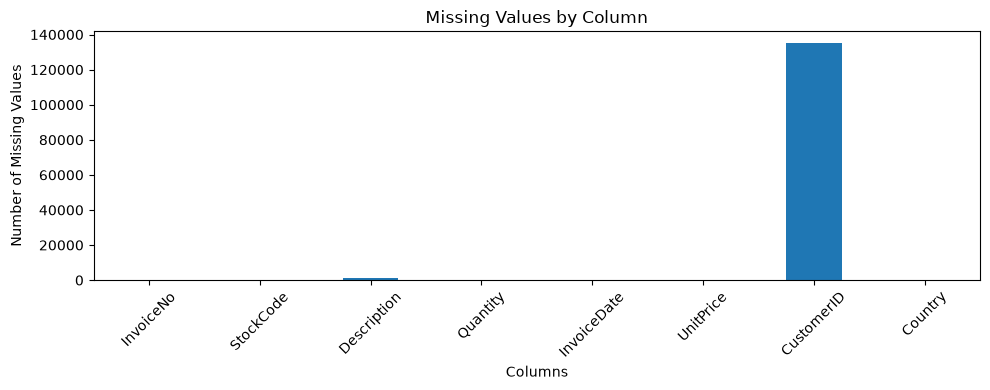

In [8]:
plt.figure(figsize=(10, 4))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Total missing values:", df.isnull().sum().sum())

print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

Total rows: 541909
Total columns: 8
Total missing values: 136534

Columns with missing values:
Description      1454
CustomerID     135080
dtype: int64

Duplicate rows: 5268


In [10]:
df_clean = df.dropna(subset=["CustomerID", "Description"]).copy()

In [11]:
cancelled_mask = (df_clean["InvoiceNo"].astype(str).str.startswith("C"))

In [12]:
# Keep rows that are not cancellations
df_clean = df_clean.loc[~cancelled_mask].copy()

In [13]:
# Find rows with zero or negative quantity or price
invalid_mask = ((df_clean["Quantity"] <= 0) |(df_clean["UnitPrice"] <= 0))

In [14]:
df_clean = df_clean.loc[(df_clean["Quantity"] > 0) &(df_clean["UnitPrice"] > 0)].copy()

In [15]:
df_clean = df_clean.drop_duplicates().copy()

In [16]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print(
    "Missing CustomerID:",
    df_clean["CustomerID"].isnull().sum()
)

print(
    "Missing Description:",
    df_clean["Description"].isnull().sum()
)

print(
    "Cancellation rows:",
    df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
)

print(
    "Invalid quantity rows:",
    (df_clean["Quantity"] <= 0).sum()
)

print(
    "Invalid price rows:",
    (df_clean["UnitPrice"] <= 0).sum()
)

print(
    "Duplicate rows:",
    df_clean.duplicated().sum()
)

Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217
Missing CustomerID: 0
Missing Description: 0
Cancellation rows: 0
Invalid quantity rows: 0
Invalid price rows: 0
Duplicate rows: 0


In [17]:
df_clean.to_csv("online_retail_cleaned.csv",index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
# 1. Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# 2. Calculate sales for each transaction line
df_clean["TotalSales"] = (df_clean["Quantity"] * df_clean["UnitPrice"])

# 3. Extract the month
df_clean["Month"] = (df_clean["InvoiceDate"].dt.to_period("M"))

# 4. Check the results
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

# 5. Save the cleaned dataset
df_clean.to_csv("online_retail_cleaned.csv",index=False)

print("Saved successfully:", os.path.exists("online_retail_cleaned.csv"))

Dataset shape: (392692, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


Saved successfully: True


Monthly Revenue:
Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalSales, dtype: float64


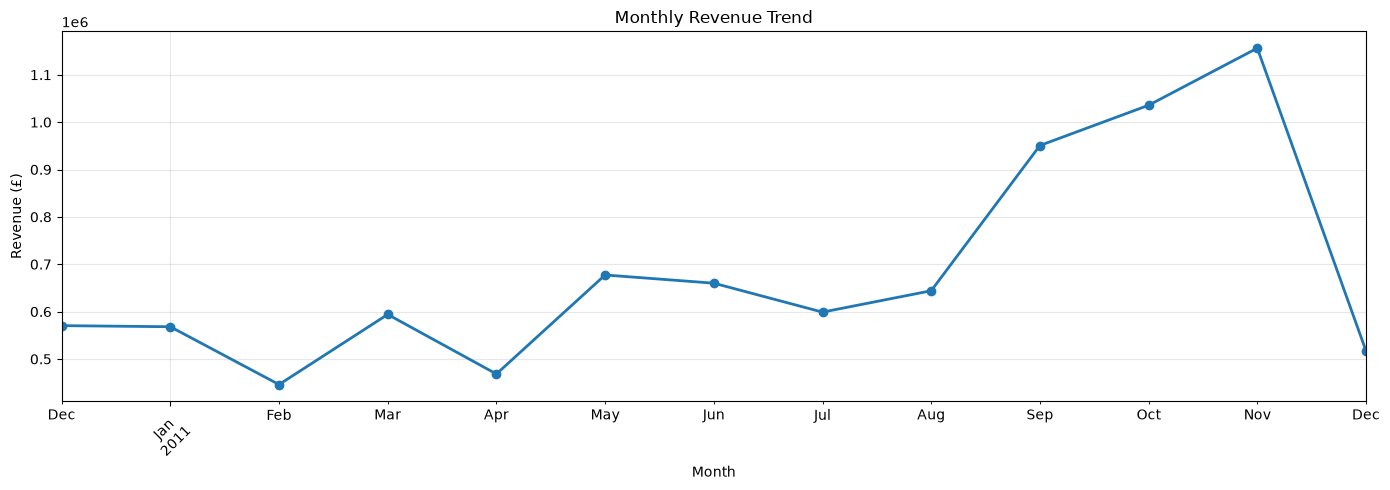

In [19]:
monthly_revenue = (df_clean.groupby("Month")["TotalSales"].sum().sort_index())

print("Monthly Revenue:")
print(monthly_revenue)

plt.figure(figsize=(14, 5))

monthly_revenue.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
best_month = monthly_revenue.idxmax()
highest_revenue = monthly_revenue.max()

print("Highest-revenue month:", best_month)
print("Highest monthly revenue: £",highest_revenue)

Highest-revenue month: 2011-11
Highest monthly revenue: £ 1156205.61


Top 10 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


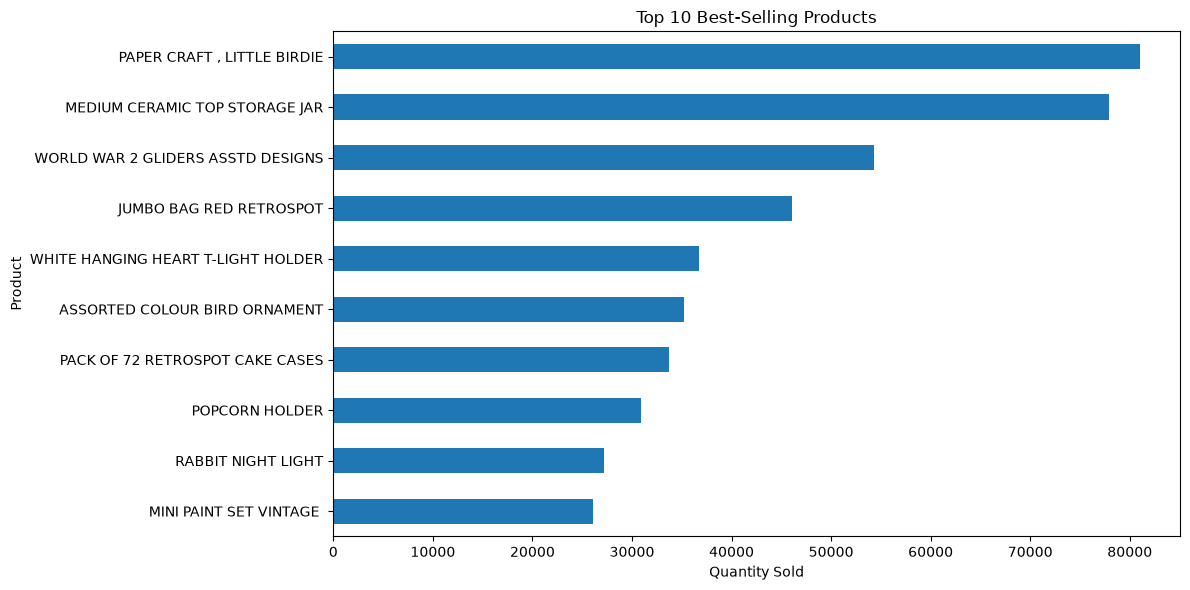

In [21]:
#top 10 products by quantity sold
top_products = (df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10))

print("Top 10 Products by Quantity Sold:")
print(top_products)

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Products by Revenue:
Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalSales, dtype: float64


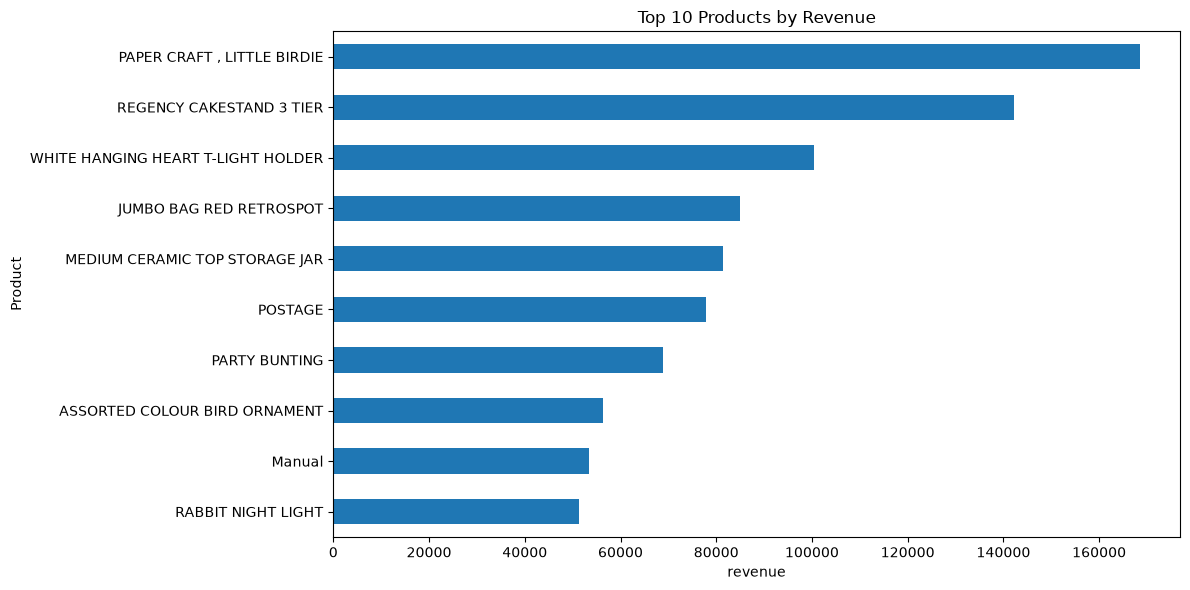

In [22]:
#top 10 product by revenue
top_products_revenue = (df_clean.groupby("Description")["TotalSales"].sum().sort_values(ascending=False).head(10))

print("Top 10 Products by Revenue:")
print(top_products_revenue)

plt.figure(figsize=(12, 6))

top_products_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()



In [23]:
#Customer Purchasing Behavior
unique_customers = df_clean["CustomerID"].nunique()

print("Total Unique Customers:", unique_customers)

Total Unique Customers: 4338


Average purchases per customer: 4.27
Maximum purchases: 209
Minimum purchases: 1


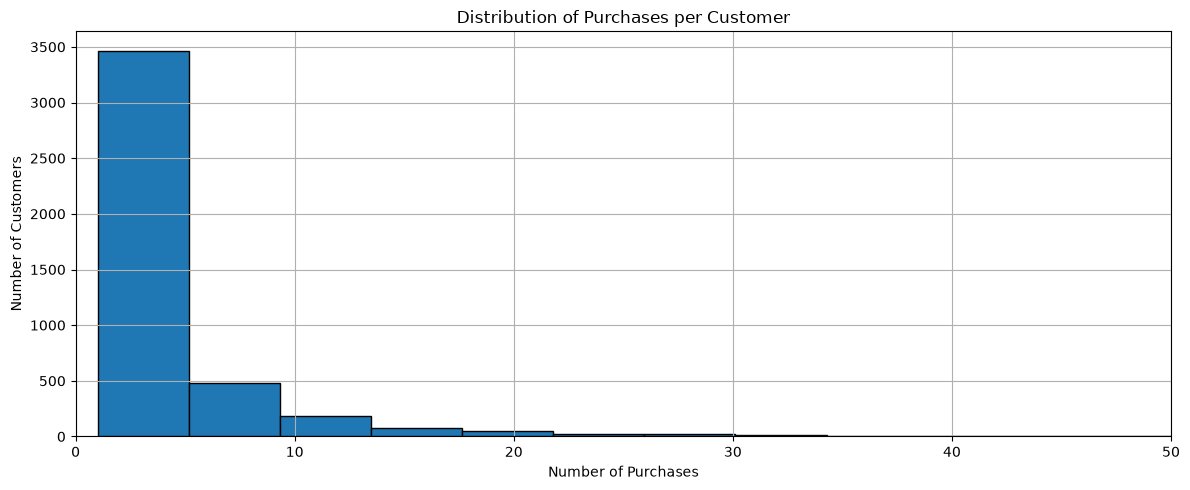

In [24]:
purchases_per_customer = (df_clean.groupby("CustomerID")["InvoiceNo"].nunique())

print("Average purchases per customer:",
      round(purchases_per_customer.mean(), 2))

print("Maximum purchases:",
      purchases_per_customer.max())

print("Minimum purchases:",
      purchases_per_customer.min())

plt.figure(figsize=(12, 5))

purchases_per_customer.hist(
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Purchases per Customer")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.xlim(0, 50)
plt.tight_layout()
plt.show()

Top 15 Countries by Revenue:
Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Japan               37416.370
Norway              36165.440
Portugal            33375.840
Finland             22546.080
Singapore           21279.290
Name: TotalSales, dtype: float64


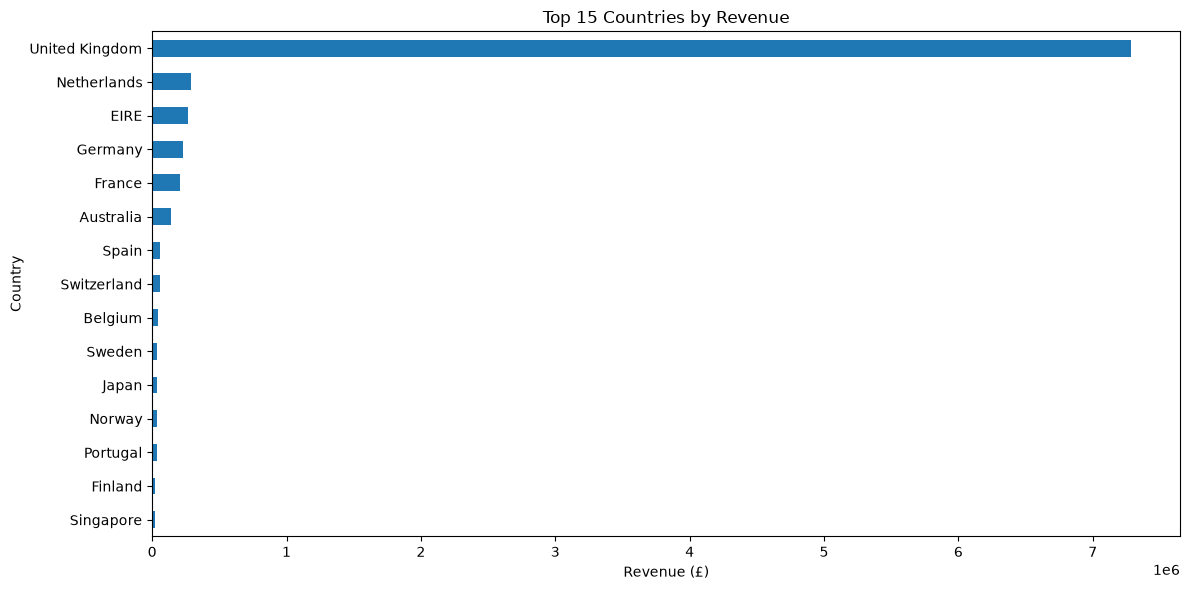

In [25]:
#Revenue by Country
revenue_by_country = (df_clean.groupby("Country")["TotalSales"].sum().sort_values(ascending=False).head(15))

print("Top 15 Countries by Revenue:")
print(revenue_by_country)

plt.figure(figsize=(12, 6))

revenue_by_country.sort_values().plot(kind="barh")

plt.title("Top 15 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [27]:
#rfm
from datetime import timedelta
reference_date = (
    df_clean["InvoiceDate"].max()
    + timedelta(days=1)
)

print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [28]:
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x:
        (reference_date - x.max()).days,

    "InvoiceNo": "count",

    "TotalSales": "sum"
})

# Give the columns meaningful names
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display the first 10 customers
display(rfm.head(10))

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,182,4310.00
12348.0,75,31,1797.24
12349.0,19,73,1757.55
12350.0,310,17,334.40
12352.0,36,85,2506.04
12353.0,204,4,89.00
12354.0,232,58,1079.40
12355.0,214,13,459.40


In [29]:
# Top 10 customers by monetary value
top_value_customers = rfm.sort_values(
    "Monetary",
    ascending=False
).head(10)

print("Top 10 Customers by Monetary Value:")
display(top_value_customers)

Top 10 Customers by Monetary Value:


,Recency,Frequency,Monetary
CustomerID,,,
14646.0,2,2076,280206.02
18102.0,1,431,259657.30
17450.0,8,336,194390.79
16446.0,1,3,168472.50
14911.0,1,5670,143711.17
12415.0,24,714,124914.53
14156.0,10,1395,117210.08
17511.0,3,963,91062.38
16029.0,39,241,80850.84


In [33]:
# Customers with the lowest recency
most_recent_customers = rfm.sort_values(
    "Recency",
    ascending=True
).head(10)

print("10 Most Recently Active Customers:")
display(most_recent_customers)

10 Most Recently Active Customers:


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
17364.0,1,406,4462.68,4,4,4,444
12433.0,1,420,13375.87,4,4,4,444
13599.0,1,246,5149.92,4,4,4,444
13536.0,1,178,3444.39,4,4,4,444
16933.0,1,44,563.23,4,3,2,432
17581.0,1,439,11025.24,4,4,4,444
15898.0,1,84,1383.83,4,3,3,433
16892.0,1,97,518.19,4,3,2,432
17644.0,1,157,2895.64,4,4,4,444


In [31]:
rfm.to_csv("customer_rfm.csv")

print("RFM analysis saved successfully!")

RFM analysis saved successfully!


In [32]:
# Step 1: Recency score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    4,
    labels=[4, 3, 2, 1],
    duplicates="drop"
)

# Step 2: Frequency score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4],
    duplicates="drop"
)

# Step 3: Monetary score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    4,
    labels=[1, 2, 3, 4],
    duplicates="drop"
)

# Step 4: Combine the scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Step 5: View the results
display(rfm.head(10))

# Step 6: Save the scored customer data
rfm.to_csv("customer_rfm_scored.csv")

print("RFM scoring completed and saved!")

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,114
12347.0,2,182,4310.00,4,4,4,444
12348.0,75,31,1797.24,2,2,4,224
12349.0,19,73,1757.55,3,3,4,334
12350.0,310,17,334.40,1,1,2,112
12352.0,36,85,2506.04,3,3,4,334
12353.0,204,4,89.00,1,1,1,111
12354.0,232,58,1079.40,1,3,3,133
12355.0,214,13,459.40,1,1,2,112


RFM scoring completed and saved!


In [38]:
#k-means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
# Select the three original RFM features
features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

# Create the scaler
scaler = StandardScaler()

# Standardize the RFM measurements
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

print("\nFirst five standardized rows:")
print(X_scaled[:5])

Original data shape: (4338, 3)
Scaled data shape: (4338, 3)

First five standardized rows:
[[ 2.33457414 -0.39703458  8.36301037]
 [-0.90534032  0.4056939   0.2516989 ]
 [-0.17535959 -0.26398566 -0.02798783]
 [-0.73534481 -0.07771717 -0.03240559]
 [ 2.17457836 -0.32607515 -0.19081155]]


In [39]:
inertias = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertias.append(kmeans.inertia_)

print("Inertia values:")
print(inertias)

Inertia values:
[13013.999999999996, 8988.615740681867, 5445.569093991164, 4010.2961622446755, 2959.861996114166, 2372.6185331607485, 1925.483987182212, 1680.97037272695, 1499.6115562571058, 1316.6670860793788]


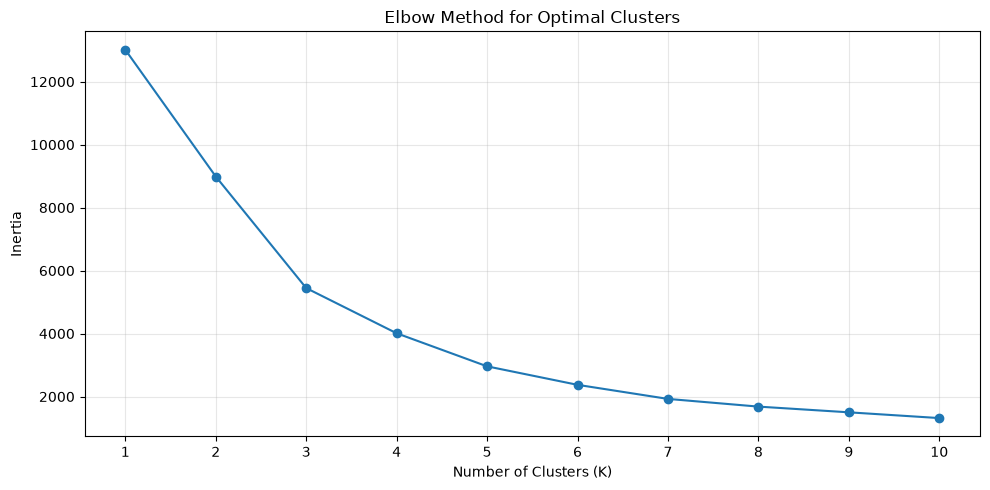

In [40]:
#Elbow Curve
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    inertias,
    marker="o"
)

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
# Create the K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_index()
)

print("Customers in each segment:")
print(segment_counts)

Customers in each segment:
Segment
0    3247
1    1081
2       6
3       4
Name: count, dtype: int64


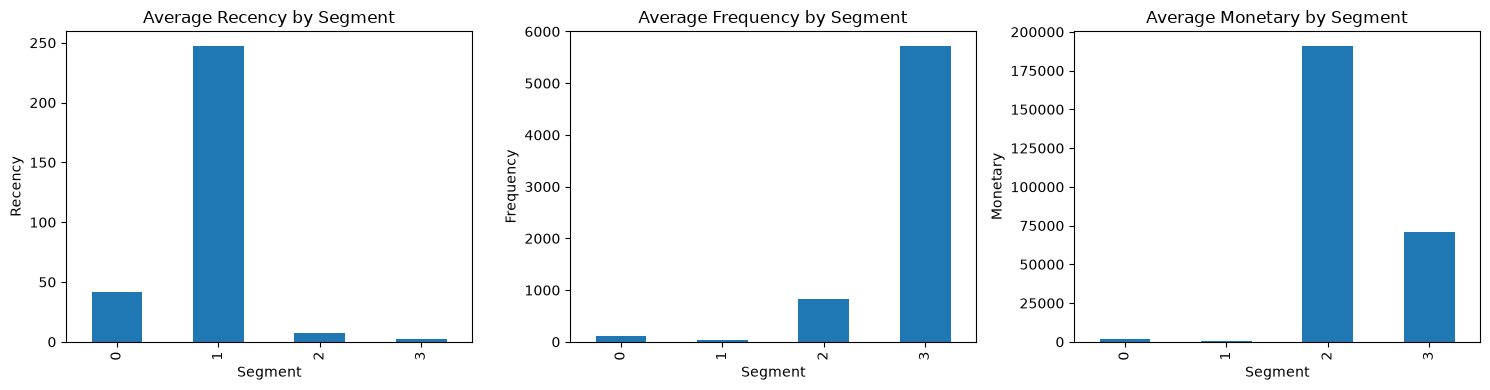

In [43]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for idx, metric in enumerate(
    ["Recency", "Frequency", "Monetary"]
):
    segment_summary[metric].plot(
        kind="bar",
        ax=axes[idx]
    )

    axes[idx].set_title(
        f"Average {metric} by Segment"
    )

    axes[idx].set_xlabel("Segment")
    axes[idx].set_ylabel(metric)

plt.tight_layout()
plt.show()

In [44]:
# Save customers with their RFM metrics and segment IDs
rfm.to_csv("customer_segments.csv")

print("Customer segments saved successfully!")

Customer segments saved successfully!


Customer percentages:
Segment
0    74.85
1    24.92
2     0.14
3     0.09
Name: count, dtype: float64


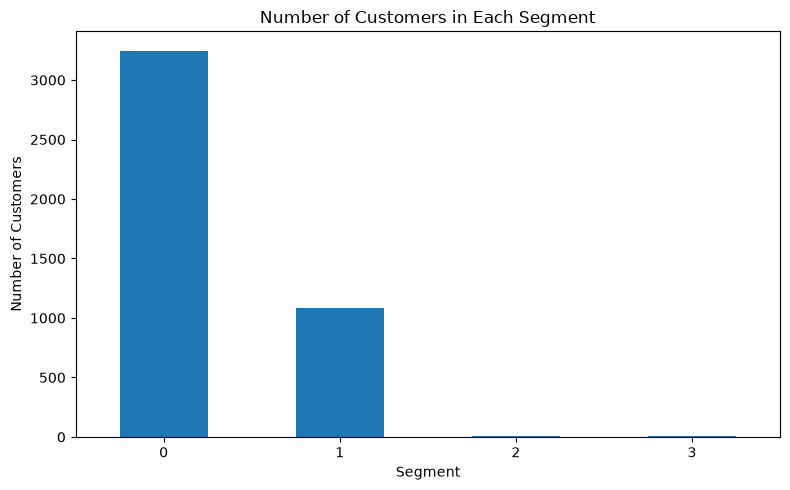

In [51]:
segment_percentages = (segment_counts / len(rfm) * 100).round(2)

print("Customer percentages:")
print(segment_percentages)

plt.figure(figsize=(8, 5))

segment_counts.plot(kind="bar")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()